# COMP0245: golden dataset experiments

This notebook starts from the frozen 300-target dataset and its 200 camera traces. It carries forward the three freshly trained baselines, iterations 34–36, as the starting point for the next experiments. The complete earlier notebook, `driving_v2_sensors.ipynb`, is preserved unchanged.

Re-running this notebook reads and plots saved results. It does not retrain models or open reserved test trajectories. The full data package is on university OneDrive; this repository contains its manifests and a small, explicitly labelled training preview. Use `GOLDEN_DATA_ROOT` for the location of the extracted package when running the training commands in `../arm/GOLDEN_DATA.md`.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
sys.path.insert(0, str(Path('../arm').resolve()))
import report_golden as golden
from report_golden import MODELS, RESULTS
GOLDEN_DATA_ROOT = Path(os.environ['GOLDEN_DATA_ROOT']).expanduser() if os.environ.get('GOLDEN_DATA_ROOT') else None
print('Full dataset:', GOLDEN_DATA_ROOT if GOLDEN_DATA_ROOT else 'not configured; saved manifests, preview and results remain available')
from IPython.display import IFrame, HTML
import uuid

def lazy_player(url, height=810):
    """A 3D player that loads only when its button is pressed. Browsers keep only about 16 3D views (WebGL
    contexts) at once, so loading every player in the notebook together leaves some of them blank."""
    k = uuid.uuid4().hex[:8]
    return HTML(f"""<div><button onclick="var f=document.getElementById('player{k}');f.src='{url}';f.style.display='block';this.style.display='none'"
 style="padding:8px 14px;font-size:14px">Load the 3D player</button>
<iframe id="player{k}" style="display:none;width:100%;height:{height}px;border:0"></iframe></div>""")


Full dataset: not configured; saved manifests, preview and results remain available


## Dataset and split

There are 100 training, 100 validation and 100 reserved test expert runs. Offline camera observations exist for training and validation. Test cameras will be rendered live along each learned trajectory in ticket #11110, so expert test camera traces are not needed. Target IDs remain fixed across comparisons.

In [2]:
split = golden.read(MODELS/'dataset_split.json')
manifest = golden.read(MODELS/'dataset_manifest.json')
audit = pd.DataFrame(golden.read(MODELS/'data_audit.json')['rows'])
assert all(len(set(v)) == 100 for v in split.values())
assert len(set().union(*map(set, split.values()))) == 300
display(pd.DataFrame([dict(split=k, expert_runs=len(v), offline_camera_runs=0 if k=='test' else len(v), role={'train':'fit weights and learned scaling','val':'choose epochs and run integration checks','test':'final evaluation only'}[k]) for k,v in split.items()]))
display(audit.groupby('split').agg(runs=('dot','count'),driving_rows=('drive_rows','sum'),arm_rows=('arm_rows','sum'),parked_tail_min=('parked_rows','min'),parked_tail_max=('parked_rows','max')))
print('Frozen split SHA256:', golden.read(MODELS/'data_audit.json')['split_sha256'])

,split,expert_runs,offline_camera_runs,role
0,train,100,100,fit weights and learned scaling
1,val,100,100,choose epochs and run integration checks
2,test,100,0,final evaluation only


,runs,driving_rows,arm_rows,parked_tail_min,parked_tail_max
split,,,,,
train,100,25928,295084,30,100
val,100,26428,288818,13,100


Frozen split SHA256: 286f578aec7e3ab0953592466e63014cc1dde7f467106fadf273b30762ac1abf


## Model inputs and training targets

Driving has 16 inputs: four accumulated encoder angles, four encoder speeds, four combinations of those readings, and camera-tracked range/sin bearing/cos bearing/visibility. Reaching has 17 inputs: seven arm encoder angles, seven encoder speeds and camera-tracked target xyz in the robot frame. Values become FP32 tensors. The camera runs at 30 Hz; its latest estimate is held between arm steps at 1 kHz.

Training targets are the expert wheel-speed and arm-torque commands, normalized time to PARK and normalized gripper distance for STOP. Simulator truth is permitted for labels and scoring; it is not fed into the learned policies.

The existing simulator retains its PD-plus-model-gravity arm hold while driving. After PARK, the learned torque network controls the arm, including the 0.5 s following STOP. That fixed pre-PARK holding controller is part of this baseline and is not a learned sensor-only arm controller. STOP does not freeze physics.

In [3]:
preview = dict(np.load(MODELS/'training_preview.npz', allow_pickle=False))
wheel_names = [f'wheel_angle_{j}_rad' for j in range(1,5)] + [f'wheel_speed_{j}_rad_s' for j in range(1,5)] + ['mean_turn_rad','right_minus_left_turn_rad','mean_speed_rad_s','right_minus_left_speed_rad_s']
drive_names = wheel_names + ['tracked_range_m','tracked_bearing_sin','tracked_bearing_cos','visible']
arm_names = [f'arm_angle_{j}_rad' for j in range(1,8)] + [f'arm_speed_{j}_rad_s' for j in range(1,8)] + ['tracked_dot_x_m','tracked_dot_y_m','tracked_dot_z_m']
print('Preview only: training target', int(preview['dot']), '; five source rows per phase, not the whole dataset.')
display(pd.DataFrame(preview['driving_x'], columns=drive_names).assign(step=preview['drive_steps']).set_index('step'))
display(pd.DataFrame(preview['arm_x'], columns=arm_names).assign(step=preview['arm_steps']).set_index('step'))
print('Input types:', preview['driving_x'].dtype, preview['arm_x'].dtype)

Preview only: training target 0 ; five source rows per phase, not the whole dataset.


,wheel_angle_1_rad,wheel_angle_2_rad,wheel_angle_3_rad,wheel_angle_4_rad,wheel_speed_1_rad_s,wheel_speed_2_rad_s,wheel_speed_3_rad_s,wheel_speed_4_rad_s,mean_turn_rad,right_minus_left_turn_rad,mean_speed_rad_s,right_minus_left_speed_rad_s,tracked_range_m,tracked_bearing_sin,tracked_bearing_cos,visible
step,,,,,,,,,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.0,0.0,0.0,0.0
33,-0.090505,0.088971,0.090505,-0.092039,-2.715146,2.669127,2.715146,-2.761165,-0.000767,-0.181010,-0.02301,-5.430292,0.0,0.0,0.0,0.0
67,-0.181010,0.179476,0.185612,-0.187146,-2.715146,2.715146,2.853204,-2.853204,-0.000767,-0.366621,0.00000,-5.568350,0.0,0.0,0.0,0.0
100,-0.268447,0.266913,0.277651,-0.279184,-2.623107,2.623107,2.761165,-2.761165,-0.000767,-0.546097,0.00000,-5.384273,0.0,0.0,0.0,0.0
133,-0.354350,0.352816,0.369689,-0.371223,-2.577088,2.577088,2.761165,-2.761165,-0.000767,-0.724039,0.00000,-5.338253,0.0,0.0,0.0,0.0


,arm_angle_1_rad,arm_angle_2_rad,arm_angle_3_rad,arm_angle_4_rad,arm_angle_5_rad,arm_angle_6_rad,arm_angle_7_rad,arm_speed_1_rad_s,arm_speed_2_rad_s,arm_speed_3_rad_s,arm_speed_4_rad_s,arm_speed_5_rad_s,arm_speed_6_rad_s,arm_speed_7_rad_s,tracked_dot_x_m,tracked_dot_y_m,tracked_dot_z_m
step,,,,,,,,,,,,,,,,,
6230,-0.014631,1.515667,0.000216,1.014285,-0.006637,1.000131,-0.001473,-0.107379,0.006818,0.049428,0.001704,-0.081812,0.000000,0.029750,0.42766,-0.034332,1.238958
6231,-0.014738,1.515657,0.000269,1.014328,-0.006721,1.000200,-0.001448,-0.107379,-0.010227,0.052837,0.042611,-0.084291,0.069417,0.024792,0.42766,-0.034332,1.238958
6232,-0.014849,1.515638,0.000320,1.014396,-0.006803,1.000322,-0.001423,-0.110788,-0.018749,0.051133,0.068177,-0.081812,0.121479,0.024792,0.42766,-0.034332,1.238958
6233,-0.014963,1.515610,0.000373,1.014485,-0.006885,1.000483,-0.001401,-0.114196,-0.027271,0.052837,0.088630,-0.081812,0.161145,0.022312,0.42619,-0.038042,1.239363
6234,-0.015081,1.515576,0.000424,1.014587,-0.006966,1.000674,-0.001376,-0.117605,-0.034088,0.051133,0.102265,-0.081812,0.190895,0.024792,0.42619,-0.038042,1.239363


Input types: float32 float32


In [4]:
display(pd.DataFrame(preview['driving_commands'], columns=[f'expert_wheel_{j}_rad_s' for j in range(1,5)]).assign(time_to_park_scaled=preview['driving_ttp'],step=preview['drive_steps']).set_index('step'))
display(pd.DataFrame(preview['arm_commands'], columns=[f'expert_torque_{j}_Nm' for j in range(1,8)]).assign(stop_distance_scaled=preview['arm_stop_target'],step=preview['arm_steps']).set_index('step'))

,expert_wheel_1_rad_s,expert_wheel_2_rad_s,expert_wheel_3_rad_s,expert_wheel_4_rad_s,time_to_park_scaled
step,,,,,
0,-3.0,3.0,3.0,-3.0,1.0
33,-3.0,3.0,3.0,-3.0,1.0
67,-3.0,3.0,3.0,-3.0,1.0
100,-3.0,3.0,3.0,-3.0,1.0
133,-3.0,3.0,3.0,-3.0,1.0


,expert_torque_1_Nm,expert_torque_2_Nm,expert_torque_3_Nm,expert_torque_4_Nm,expert_torque_5_Nm,expert_torque_6_Nm,expert_torque_7_Nm,stop_distance_scaled
step,,,,,,,,
6230,5.316199,28.082699,-1.365561,-6.598114,3.302955,22.673250,-0.699793,1.0
6231,5.320834,28.591558,-1.470603,-7.839973,3.385210,20.551292,-0.551579,1.0
6232,5.459431,28.937777,-1.435724,-8.689305,3.328572,19.007622,-0.613395,1.0
6233,5.542691,29.200615,-1.472973,-9.291978,3.338620,17.821453,-0.567547,1.0
6234,5.643270,29.394722,-1.480658,-9.713266,3.327830,16.905899,-0.562102,1.0


## Frozen baselines

The following results are copied from the completed golden-data training and validation work. No new training was started to create this notebook. The source notebook remains unchanged. Each seed has the same analysis and its own lazy player, so the browser does not load every 3D view at once.

### Golden data: driving and reaching, three seeds (iterations 34 to 36)

#### Iterations 34 to 36: plan and expected results

Written before training. Ticket #11109 follows the 4 November roadmap: retrain the iteration 13 driving architecture and iteration 27 reaching architecture on 100 training runs, choose epochs on 100 validation runs, and reserve the 100 test runs for ticket #11110. Seeds 7, 1 and 2 are iterations 34, 35 and 36 respectively. Earlier notebook results stay unchanged.

Driving uses 16 encoder/camera inputs at 30 Hz, two 16-unit ReLU layers, four wheel-speed outputs and a separate time-to-PARK head. The target is seconds to the recorded PARK, clipped at 3 s and divided by 3; the PARK threshold remains 0.25 s. The loss is wheel-speed MSE plus normalized time-to-PARK MSE, with each run weighted equally. Include at most 100 available, real parked frames after PARK. Fit the six angle-feature scales on training only.

Reaching uses 17 inputs at 1 kHz: seven encoder angles, seven encoder speeds and camera/tracker xyz, held between camera frames. Its torque path has two 64-unit ReLU layers and seven torque outputs; the independent stop network is 17 -> 32 -> 16 -> 1. Preserve the inherited auxiliary distance loss when training the torque path; the independent stop network supplies runtime STOP. Both distance targets use the aligned expert distance, clipped at 0.25 m and divided by 0.25; STOP remains 10 mm. Each run has equal weight. Encoder resolutions, fixed input scales and runtime clipping remain unchanged.

Every network starts from fresh weights. Use FP32, Adam at 0.01, up to 300 epochs for driving/torques and 600 for independent stop. Select the lowest declared validation objective and restore that checkpoint. Any chunking accumulates the same full-batch gradient before one optimizer update. Validate exported NumPy predictions against PyTorch before simulation.

Expected result: validation losses should fall below their epoch-zero values, and the broader range of target heights should reduce the single-height behaviour seen in iteration 30. This is a hypothesis, not a claimed result. It is contradicted if validation does not improve, or if recorded validation reaches continue to converge to one height regardless of the camera estimate. A lower offline loss alone does not establish successful parking or reaching.

Use a fixed validation subset, selected before training, for full learned drive/PARK/reach/STOP demonstrations. The expert is only a recorded reference/ghost. Report every seed, camera visibility, PARK, STOP, distance at STOP and timeouts; never tune against the reserved test runs. There is no PPO, weight perturbation, new CNN, DART or DAgger in this experiment.

Status: all three seeds trained on the GPU in 87.7 seconds including loading and export checks. The results below are validation simulations only. The 100 test trajectories were not opened.

#### Golden data: checks and training setup

The source and camera hashes matched for all 100 training and 100 validation runs. Camera observations were replayed at their recorded 30 Hz capture times and held between frames; arm encoders use a 1 ms backward difference. The wheel speeds retain the existing nominal 1/30 s denominator at rounded frame steps, matching the recorded features and runtime. No new scaling convention was introduced.

Some runs end before 100 parked camera frames are available. We use only the real recorded tail: 30–100 frames in training and 13–100 in validation. No synthetic tail or repeated row was added. Each run contributes equally to the objective.

This clean notebook contains the golden-data experiment only. Its analysis rereads the frozen outputs; training is a separate explicit command.

In [5]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
sys.path.insert(0, str(Path('../arm').resolve()))
import report_golden as golden
from report_golden import MODELS, RESULTS
training = golden.read(MODELS/'summary.json')
audit = pd.DataFrame(golden.read(MODELS/'data_audit.json')['rows'])
display(audit.groupby('split').agg(runs=('dot','count'), driving_rows=('drive_rows','sum'), arm_rows=('arm_rows','sum'), min_parked_frames=('parked_rows','min'), max_parked_frames=('parked_rows','max')))
print('Training wall time:', round(training['elapsed_s'],1), 'seconds; representative seed:', training['representative_seed'])
print('Test trajectories opened:', golden.read(MODELS/'data_audit.json')['test_trajectories_opened'])

,runs,driving_rows,arm_rows,min_parked_frames,max_parked_frames
split,,,,,
train,100,25928,295084,30,100
val,100,26428,288818,13,100


Training wall time: 87.7 seconds; representative seed: 7
Test trajectories opened: 0


#### Iteration 34: golden data, seed 7, results

The same 10 validation targets were fixed before training. Both learned networks control the robot; the recorded expert is only the comparison. Success requires PARK, STOP and actual gripper distance at STOP of at most 10 mm. The subsequent hold and drift do not change that score.

In [6]:
display(golden.table(7).round(3))

,parked,park_s,park_error_cm,stop_s,at_stop_mm,closest_mm,end_mm,success,camera_visible_fraction,elapsed_s
dot,,,,,,,,,,
6,False,NaN,NaN,NaN,NaN,NaN,4208.246,False,0.000,19.529
131,False,NaN,NaN,NaN,NaN,NaN,4790.008,False,0.000,20.079
204,False,NaN,NaN,NaN,NaN,NaN,4529.255,False,0.000,19.265
268,False,NaN,NaN,NaN,NaN,NaN,4295.174,False,0.000,18.708
374,False,NaN,NaN,NaN,NaN,NaN,4063.391,False,0.000,18.454
506,True,8.133,42.273,9.427,662.505,577.694,702.714,False,0.923,14.422
587,True,4.167,12.980,4.790,124.919,102.076,222.339,False,0.862,8.880
676,False,NaN,NaN,NaN,NaN,NaN,3413.383,False,0.000,17.313
823,True,5.233,12.807,6.512,514.380,446.754,676.080,False,1.000,10.663


#### Iteration 34: loss curves

Solid lines are training and dashed lines are validation. Vertical markers show the independently selected checkpoints. The torque path retains its auxiliary distance loss, while the separate distance network supplies runtime STOP. The final test set is absent from these curves.

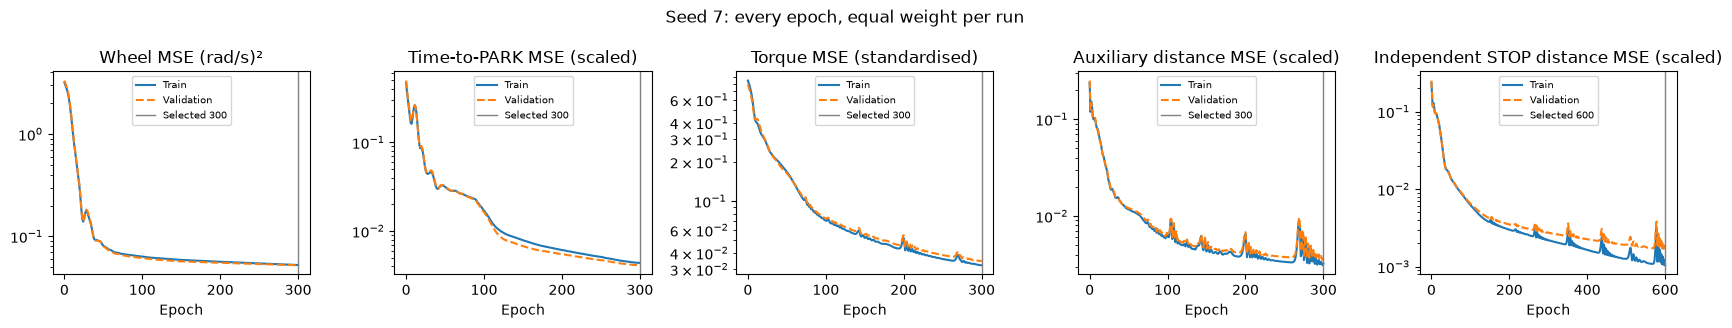

In [7]:
golden.losses(7); plt.show()

#### Iteration 34: parking, reaching and camera visibility

Blank parking bars mean the model did not PARK. Distance statistics apply only where reaching started; the full-task denominator remains 10. The visibility fraction is measured from rendered images, not from known target coordinates.

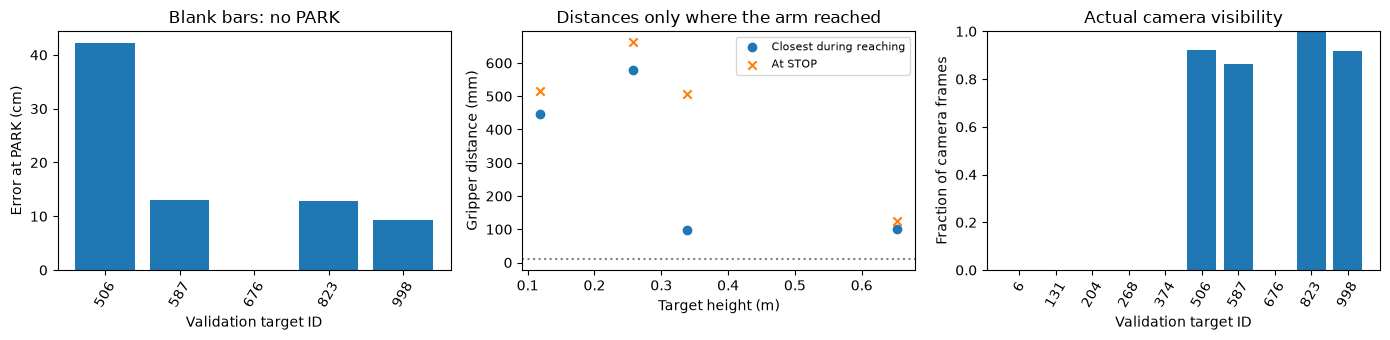

In [8]:
golden.outcomes(7); plt.show()

#### Iteration 34: predicted and actual stopping distance

Actual distance is used only for scoring. The predicted distance comes from the stop network. The vertical line is STOP; the dotted horizontal line is 10 mm. The historical log key `ttp_s` now carries distance in metres for this distance-stop model, so it is converted to mm here.

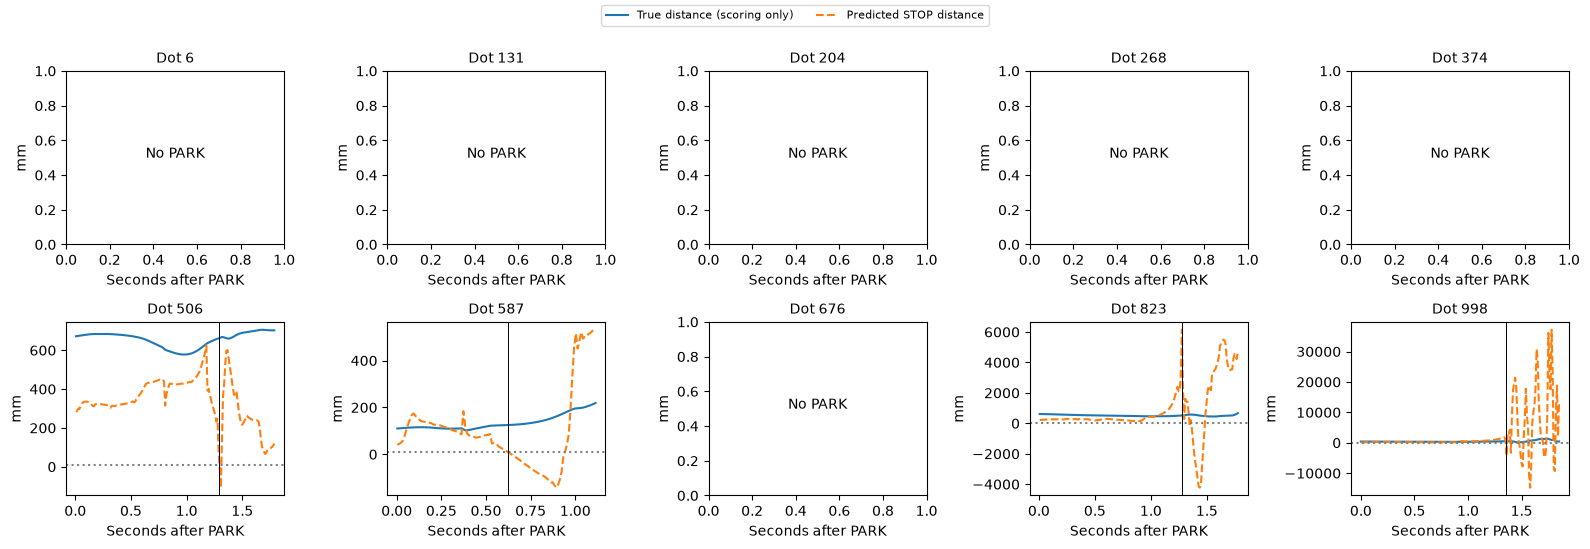

In [9]:
golden.distances(7); plt.show()

#### Iteration 34: 3D replay with ghost expert and camera

The player contains every recorded validation trajectory without cutting off failures. It loads only when requested. The top-right image is the camera frame captured along the model's actual motion, reduced from 256 px to 128 px for display; detection used the full image.

In [10]:
player_path = golden.build_viewer(7)
player_url = '/files/arm/results/golden_11109/' + player_path.name
display(HTML(f'<a href="{player_url}" target="_blank">Open the seed 7 player separately</a>'))
display(lazy_player(player_url))

#### Iteration 34: reading the results

In [11]:
display(Markdown(golden.reading(7)))

Validation losses fell: driving 3.824 to 0.05626 (epoch 300); torque 1.038 to 0.0382 (epoch 300); stop 0.2512 to 0.001658 (epoch 600). In the 10 predetermined simulation checks, 4/10 parked, 4/10 issued STOP, and 0/10 stopped within 10 mm. There was 511 mm median distance at STOP across the 4 runs that stopped. Missing PARK or STOP is a failed full task, not a missing observation to discard. These are integration checks on validation targets, not the final 100-target test score. A better offline fit has not established reliable end-to-end reaching. The untouched test evaluation is ticket #11110.

#### Iteration 35: golden data, seed 1, results

The same 10 validation targets were fixed before training. Both learned networks control the robot; the recorded expert is only the comparison. Success requires PARK, STOP and actual gripper distance at STOP of at most 10 mm. The subsequent hold and drift do not change that score.

In [12]:
display(golden.table(1).round(3))

,parked,park_s,park_error_cm,stop_s,at_stop_mm,closest_mm,end_mm,success,camera_visible_fraction,elapsed_s
dot,,,,,,,,,,
6,True,8.833,31.177,10.470,134.386,116.114,127.963,False,0.685,15.756
131,True,7.333,52.446,9.318,1477.819,617.023,1065.524,False,0.607,14.632
204,True,8.400,38.241,NaN,NaN,445.983,728.904,False,0.808,19.280
268,True,10.033,32.301,NaN,NaN,391.244,512.963,False,0.578,19.101
374,True,7.033,18.590,10.657,566.591,296.321,571.398,False,0.833,15.909
506,True,5.033,39.056,8.935,1010.400,565.693,1094.893,False,0.930,14.263
587,True,4.600,2.000,6.540,981.281,71.855,1031.870,False,0.958,10.845
676,True,5.533,16.005,NaN,NaN,20.541,256.931,False,0.808,16.898
823,True,4.200,5.481,9.385,283.887,161.203,161.125,False,0.980,14.471


#### Iteration 35: loss curves

Solid lines are training and dashed lines are validation. Vertical markers show the independently selected checkpoints. The torque path retains its auxiliary distance loss, while the separate distance network supplies runtime STOP. The final test set is absent from these curves.

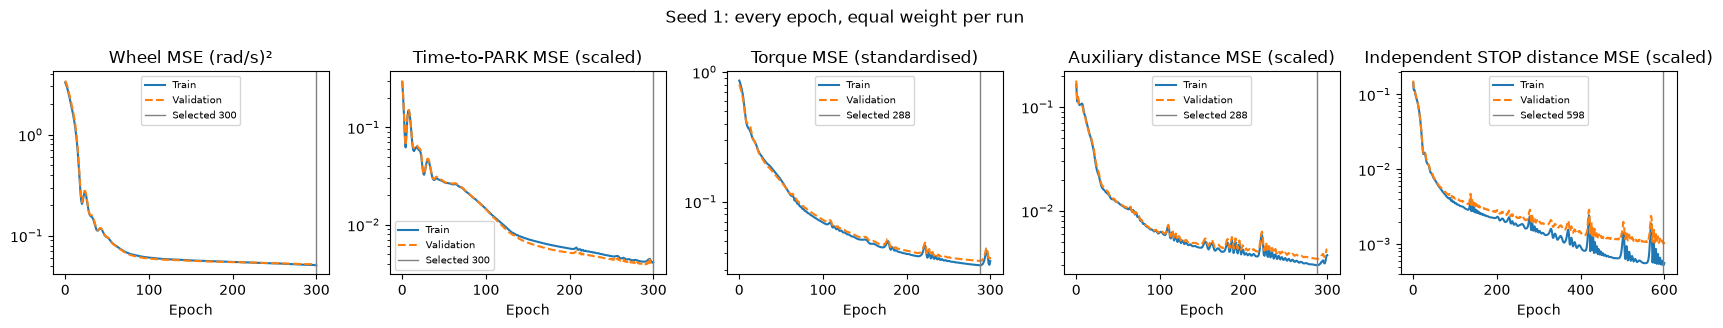

In [13]:
golden.losses(1); plt.show()

#### Iteration 35: parking, reaching and camera visibility

Blank parking bars mean the model did not PARK. Distance statistics apply only where reaching started; the full-task denominator remains 10. The visibility fraction is measured from rendered images, not from known target coordinates.

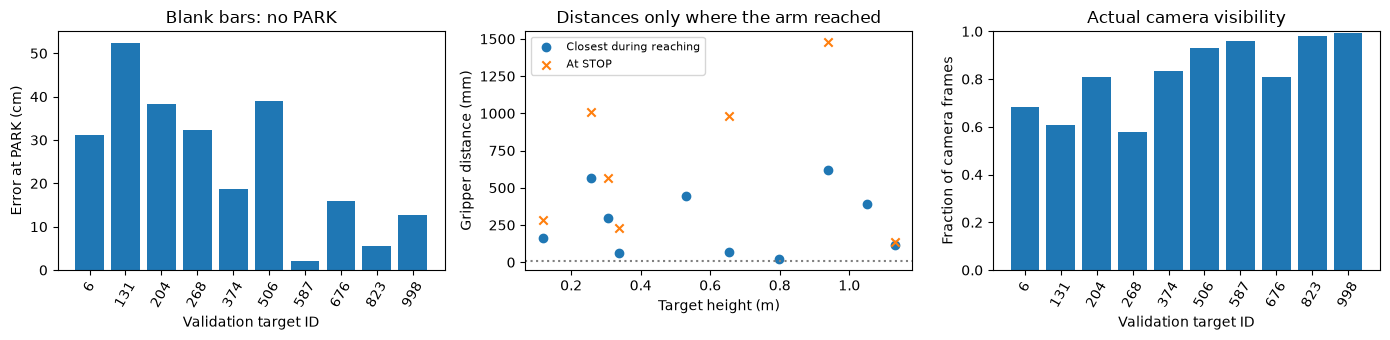

In [14]:
golden.outcomes(1); plt.show()

#### Iteration 35: predicted and actual stopping distance

Actual distance is used only for scoring. The predicted distance comes from the stop network. The vertical line is STOP; the dotted horizontal line is 10 mm. The historical log key `ttp_s` now carries distance in metres for this distance-stop model, so it is converted to mm here.

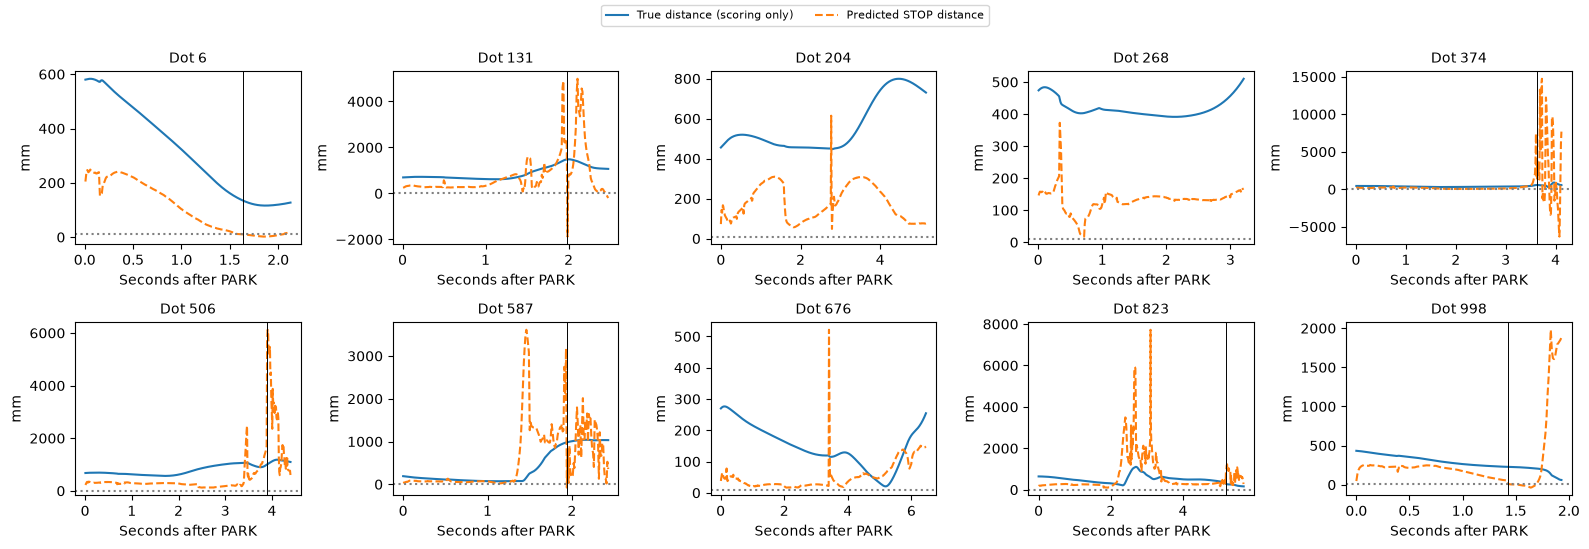

In [15]:
golden.distances(1); plt.show()

#### Iteration 35: 3D replay with ghost expert and camera

The player contains every recorded validation trajectory without cutting off failures. It loads only when requested. The top-right image is the camera frame captured along the model's actual motion, reduced from 256 px to 128 px for display; detection used the full image.

In [16]:
player_path = golden.build_viewer(1)
player_url = '/files/arm/results/golden_11109/' + player_path.name
display(HTML(f'<a href="{player_url}" target="_blank">Open the seed 1 player separately</a>'))
display(lazy_player(player_url))

#### Iteration 35: reading the results

In [17]:
display(Markdown(golden.reading(1)))

Validation losses fell: driving 3.734 to 0.05583 (epoch 300); torque 0.9775 to 0.03844 (epoch 288); stop 0.1533 to 0.001015 (epoch 598). In the 10 predetermined simulation checks, 10/10 parked, 7/10 issued STOP, and 0/10 stopped within 10 mm. There was 567 mm median distance at STOP across the 7 runs that stopped. Missing PARK or STOP is a failed full task, not a missing observation to discard. These are integration checks on validation targets, not the final 100-target test score. A better offline fit has not established reliable end-to-end reaching. The untouched test evaluation is ticket #11110.

#### Iteration 36: golden data, seed 2, results

The same 10 validation targets were fixed before training. Both learned networks control the robot; the recorded expert is only the comparison. Success requires PARK, STOP and actual gripper distance at STOP of at most 10 mm. The subsequent hold and drift do not change that score.

In [18]:
display(golden.table(2).round(3))

,parked,park_s,park_error_cm,stop_s,at_stop_mm,closest_mm,end_mm,success,camera_visible_fraction,elapsed_s
dot,,,,,,,,,,
6,True,5.233,48.670,13.296,1768.190,525.444,1166.853,False,0.800,20.509
131,True,8.000,54.903,10.214,479.916,479.268,505.060,False,0.652,15.707
204,True,10.267,3.843,NaN,NaN,143.221,572.360,False,0.843,18.966
268,True,11.400,8.799,12.958,269.493,121.851,560.140,False,0.520,18.387
374,True,10.133,31.693,13.324,782.514,291.282,883.650,False,0.904,18.872
506,True,7.300,11.482,12.455,1080.763,24.126,1030.321,False,0.992,18.791
587,True,6.500,20.838,7.015,258.240,226.452,246.977,False,0.681,11.941
676,True,9.733,36.906,9.786,437.288,358.159,357.977,False,0.722,14.588
823,True,5.900,9.060,8.577,108.622,106.571,119.832,False,0.905,13.009


#### Iteration 36: loss curves

Solid lines are training and dashed lines are validation. Vertical markers show the independently selected checkpoints. The torque path retains its auxiliary distance loss, while the separate distance network supplies runtime STOP. The final test set is absent from these curves.

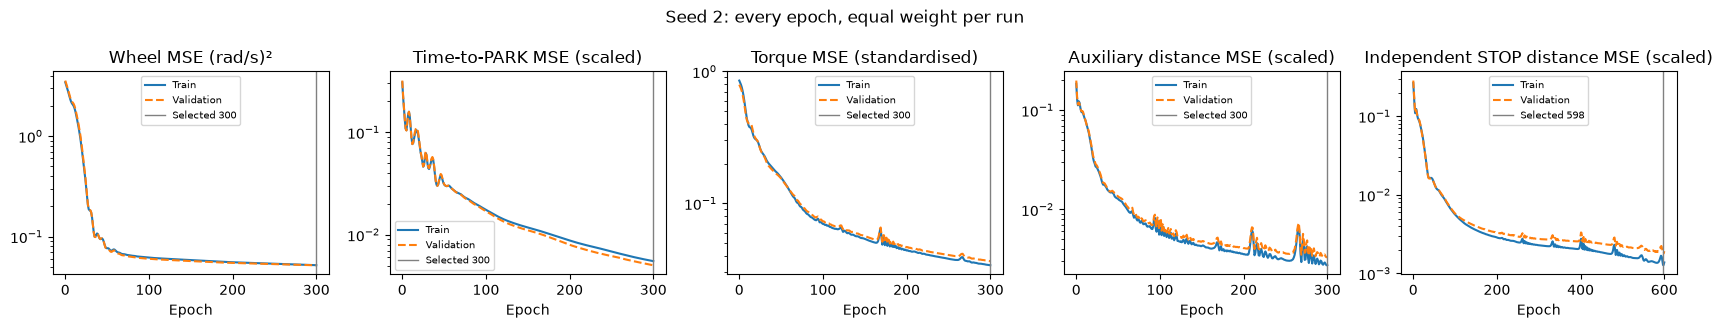

In [19]:
golden.losses(2); plt.show()

#### Iteration 36: parking, reaching and camera visibility

Blank parking bars mean the model did not PARK. Distance statistics apply only where reaching started; the full-task denominator remains 10. The visibility fraction is measured from rendered images, not from known target coordinates.

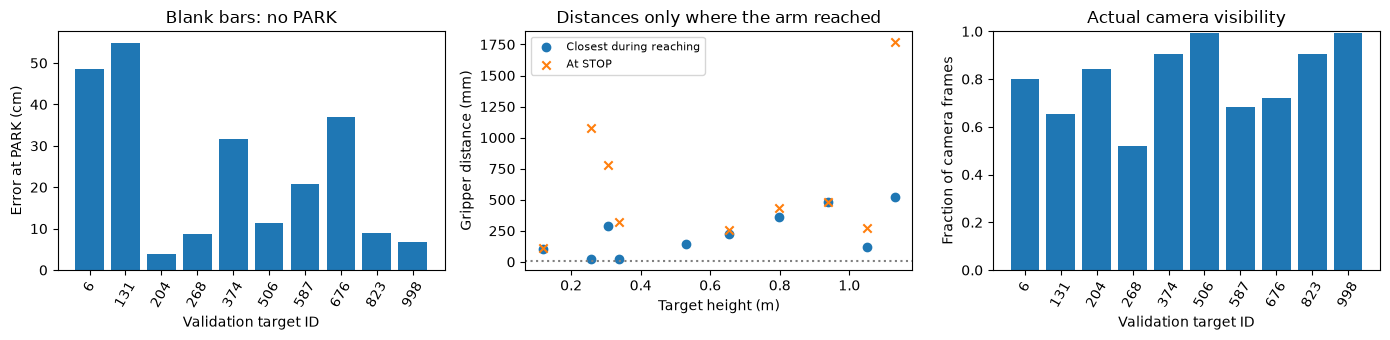

In [20]:
golden.outcomes(2); plt.show()

#### Iteration 36: predicted and actual stopping distance

Actual distance is used only for scoring. The predicted distance comes from the stop network. The vertical line is STOP; the dotted horizontal line is 10 mm. The historical log key `ttp_s` now carries distance in metres for this distance-stop model, so it is converted to mm here.

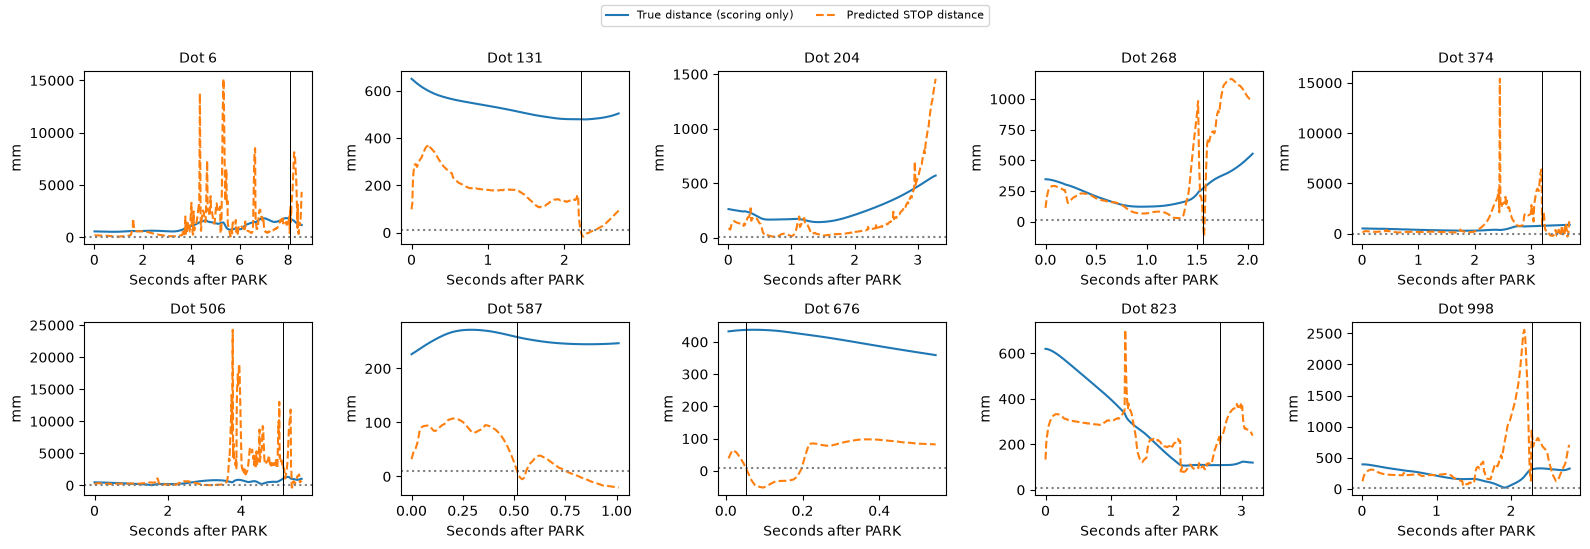

In [21]:
golden.distances(2); plt.show()

#### Iteration 36: 3D replay with ghost expert and camera

The player contains every recorded validation trajectory without cutting off failures. It loads only when requested. The top-right image is the camera frame captured along the model's actual motion, reduced from 256 px to 128 px for display; detection used the full image.

In [22]:
player_path = golden.build_viewer(2)
player_url = '/files/arm/results/golden_11109/' + player_path.name
display(HTML(f'<a href="{player_url}" target="_blank">Open the seed 2 player separately</a>'))
display(lazy_player(player_url))

#### Iteration 36: reading the results

In [23]:
display(Markdown(golden.reading(2)))

Validation losses fell: driving 3.887 to 0.05693 (epoch 300); torque 0.9929 to 0.03982 (epoch 300); stop 0.2839 to 0.00179 (epoch 598). In the 10 predetermined simulation checks, 10/10 parked, 9/10 issued STOP, and 0/10 stopped within 10 mm. There was 437 mm median distance at STOP across the 9 runs that stopped. Missing PARK or STOP is a failed full task, not a missing observation to discard. These are integration checks on validation targets, not the final 100-target test score. A better offline fit has not established reliable end-to-end reaching. The untouched test evaluation is ticket #11110.

#### Golden data: three-seed comparison and next step

Seed 7 is the median of the sum of the three selected validation objectives, chosen before simulation. It is not the best parking result. Keep that distinction when comparing later fixed-model interventions. These three initialisations are not three independent datasets.

The offline learning check passed, but none of these 30 validation attempts achieved the 10 mm full-task goal. This experiment does not establish reliable end-to-end reaching. Final test evaluation remains a separate frozen run in ticket #11110; no new optimisation was performed in response to these validation outcomes.

In [24]:
summary=[]
for seed in (7,1,2):
    d=golden.table(seed)
    summary.append(dict(seed=seed,attempts=len(d),parked=int(d.parked.sum()),stopped=int(d.stop_s.notna().sum()),success_10mm=int(d.success.sum()),median_park_error_cm=d.park_error_cm.median(),median_stop_mm=d.at_stop_mm.median()))
display(pd.DataFrame(summary).set_index('seed').round(2))

,attempts,parked,stopped,success_10mm,median_park_error_cm,median_stop_mm
seed,,,,,,
7,10,4,4,0,12.89,511.17
1,10,10,7,0,24.88,566.59
2,10,10,9,0,16.16,437.29


## Next experiments

The baseline models are fixed. Ticket #11110 evaluates all 100 reserved test targets for each seed. Later tickets add the declared noise and visibility conditions, with validation used for any training choice. Add each new hypothesis, result and replay below this point; keep the baselines above intact.

The lighthouse experiment will alternate target visibility during driving and keep it visible after PARK. This is a visual-only intervention. The training losses remain MSE against the expert targets; the 10 mm-at-STOP criterion is an evaluation measure.